# Три классификатора на одних данных: наивный Байес, логистическая регрессия, линейный SVM

**Курс:** «Интеллектуальный анализ текстов: от статистических моделей языка до языковых агентов». Блокнот относится к лекции 2 «Классические задачи анализа текста» и разворачивает слайд «Три классификатора на одних данных».

## Цель

Понять, как три классических метода проводят границу между классами, чем эти границы различаются и как это проявляется на текстах. Все три метода применяются к одним и тем же данным, поэтому различия видны на рисунках.

## План

| Часть | Содержание |
|---|---|
| 1 | Данные: две группы точек на плоскости |
| 2 | Наивный байесовский классификатор: теория и пример |
| 3 | Логистическая регрессия: теория и пример |
| 4 | Линейный метод опорных векторов (SVM): теория и пример |
| 5 | Три метода рядом, реакция на удалённые точки |
| 6 | Те же три метода на текстах: рубрика новости |
| 7 | Шесть вопросов для письменного ответа |

В частях 1–5 у объекта два числовых признака, и границу можно нарисовать. В части 6 объектом становится текст новости с несколькими тысячами признаков, по одному на слово. Методы при этом те же.

## Общая постановка

Дана обучающая выборка: объекты $x_1,\dots,x_n$ и их метки классов $y_1,\dots,y_n$. Объект описан вектором признаков $x=(x^{(1)},\dots,x^{(m)})$. Классов два, они обозначены 0 и 1. Требуется построить правило, которое по признакам нового объекта предсказывает его класс. Множество точек, в которых правило меняет ответ, называется границей между классами.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
SEED = 42

BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#6b7280", "#e5e7eb"
# расходящаяся шкала для вероятности класса 1: синий (класс 0), серый (0.5), оранжевый (класс 1)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#cfe0f7", "#f0f0ee", "#f9d5c5", "#eb6834"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
print("Готово")

Готово


## Часть 1. Данные

Две группы точек на плоскости. Класс 0 показан синим, класс 1 оранжевым. Группы немного перекрываются, и у них разный разброс: класс 1 сильнее вытянут по вертикали. Данные делятся на обучающую часть (70 %) и тестовую (30 %) с сохранением долей классов. Модели обучаются на обучающей части, качество измеряется на тестовой.

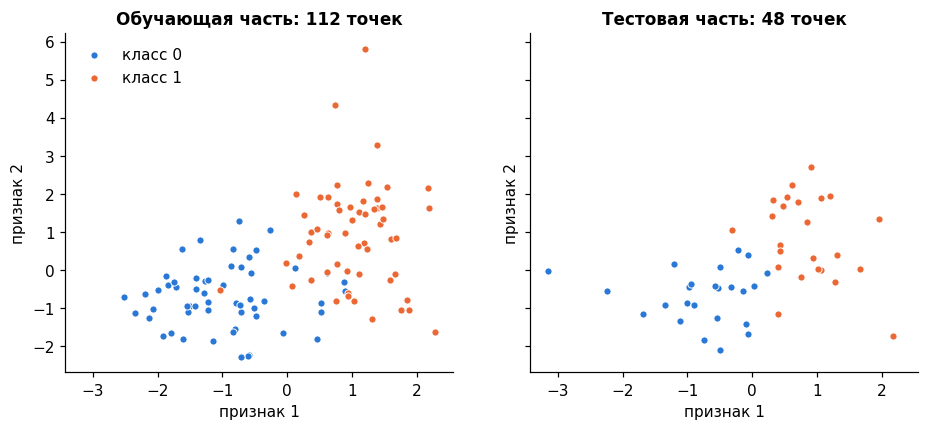

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.RandomState(SEED)
X0 = rng.normal(loc=[-0.8, -0.7], scale=[0.9, 0.8], size=(80, 2))     # класс 0
X1 = rng.normal(loc=[0.9, 0.8], scale=[0.6, 1.3], size=(80, 2))       # класс 1
X = np.vstack([X0, X1])
y = np.array([0] * 80 + [1] * 80)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)


def scatter(ax, X, y, **kw):
    for cls, col, name in [(0, BLUE, "класс 0"), (1, ORANGE, "класс 1")]:
        ax.scatter(X[y == cls, 0], X[y == cls, 1], s=22, color=col, edgecolor="white", linewidth=0.6, label=name, **kw)
    ax.set_xlabel("признак 1"); ax.set_ylabel("признак 2")


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
scatter(axes[0], X_train, y_train); axes[0].set_title(f"Обучающая часть: {len(y_train)} точек"); axes[0].legend(frameon=False)
scatter(axes[1], X_test, y_test); axes[1].set_title(f"Тестовая часть: {len(y_test)} точек")
plt.show()

In [3]:
XLIM, YLIM = (-4.5, 4.5), (-4.5, 5.5)
gx, gy = np.meshgrid(np.linspace(*XLIM, 300), np.linspace(*YLIM, 300))
GRID_POINTS = np.c_[gx.ravel(), gy.ravel()]


def plot_proba(ax, clf, X, y, title=""):
    # Закрашивает плоскость вероятностью класса 1 и рисует границу, на которой она равна 0.5.
    p = clf.predict_proba(GRID_POINTS)[:, 1].reshape(gx.shape)
    im = ax.contourf(gx, gy, p, levels=np.linspace(0, 1, 11), cmap=DIV, alpha=0.9)
    ax.contour(gx, gy, p, levels=[0.5], colors="#1f2430", linewidths=1.8)
    scatter(ax, X, y)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_title(title)
    return im


def accuracy(clf, X, y):
    return float((clf.predict(X) == y).mean())

## Часть 2. Наивный байесовский классификатор

### Теория

Метод отвечает на вопрос, какой класс вероятнее для объекта с данными признаками. Ответ даёт теорема Байеса:

$$P(c\mid x)=\frac{P(c)\,P(x\mid c)}{P(x)}.$$

- $P(c)$ называется априорной вероятностью класса. Она равна доле класса в обучающей выборке.
- $P(x\mid c)$ показывает, насколько типичны такие признаки для класса $c$.
- $P(x)$ одинакова для всех классов, поэтому при сравнении классов её можно опустить.

Оценить $P(x\mid c)$ для всех сочетаний признаков сразу невозможно: сочетаний слишком много. Метод делает упрощающее предположение: **при известном классе признаки независимы**. Тогда вероятность сочетания равна произведению вероятностей отдельных признаков:

$$P(x\mid c)=\prod_{j=1}^{m}P\big(x^{(j)}\mid c\big).$$

Это предположение почти никогда не выполняется точно, отсюда слово «наивный». Правило классификации: выбрать класс с наибольшим значением $P(c)\prod_j P(x^{(j)}\mid c)$. На практике перемножение заменяют суммой логарифмов, чтобы произведение многих малых чисел не обратилось в машинный ноль.

Вид $P(x^{(j)}\mid c)$ зависит от типа признаков.

- Для числовых признаков, как в этой части, берут нормальное распределение. Для каждого класса и каждого признака по обучающим данным оцениваются среднее $\mu$ и дисперсия $\sigma^2$. Это гауссовский наивный Байес (`GaussianNB`).
- Для счётчиков слов, как в части 6, берут частоту слова в текстах класса со сглаживанием Лапласа. Это мультиномиальный наивный Байес (`MultinomialNB`).

Обучение сводится к подсчёту средних, дисперсий и частот. Оптимизации нет, поэтому метод обучается за один проход по данным.

In [4]:
from scipy.stats import norm
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB().fit(X_train, y_train)
params = pd.DataFrame({
    "априорная вероятность P(c)": nb.class_prior_,
    "среднее признака 1": nb.theta_[:, 0], "среднее признака 2": nb.theta_[:, 1],
    "ст. отклонение признака 1": np.sqrt(nb.var_[:, 0]), "ст. отклонение признака 2": np.sqrt(nb.var_[:, 1]),
}, index=["класс 0", "класс 1"])
display(params.round(2))

# Расчёт вручную для одной точки: логарифм априорной вероятности плюс сумма логарифмов плотностей признаков
point = np.array([0.3, -0.2])
log_score = np.log(nb.class_prior_) + norm.logpdf(point, loc=nb.theta_, scale=np.sqrt(nb.var_)).sum(axis=1)
posterior = np.exp(log_score - log_score.max()); posterior /= posterior.sum()
print("Точка", point)
print("  сумма логарифмов для классов 0 и 1:", np.round(log_score, 3))
print("  вероятности классов, расчёт вручную:", np.round(posterior, 3))
print("  вероятности классов, sklearn:       ", np.round(nb.predict_proba([point])[0], 3))

,априорная вероятность P(c),среднее признака 1,среднее признака 2,ст. отклонение признака 1,ст. отклонение признака 2
класс 0,0.5,-0.98,-0.71,0.82,0.81
класс 1,0.5,1.03,0.90,0.61,1.36


Точка [ 0.3 -0.2]
  сумма логарифмов для классов 0 и 1: [-3.541 -3.382]
  вероятности классов, расчёт вручную: [0.461 0.539]
  вероятности классов, sklearn:        [0.461 0.539]


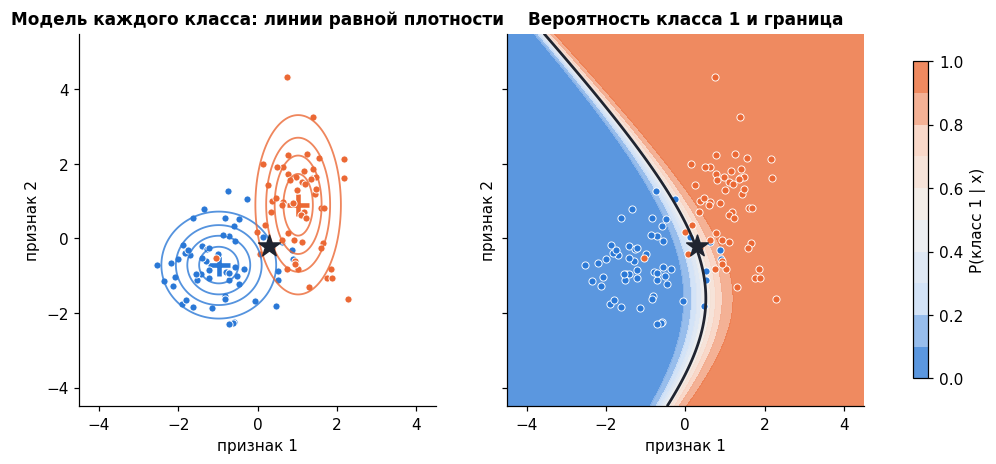

Доля верных ответов: обучение 0.920, тест 0.958


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True, sharey=True)
ax = axes[0]
for cls, col in [(0, BLUE), (1, ORANGE)]:
    dens = np.exp(norm.logpdf(GRID_POINTS, loc=nb.theta_[cls], scale=np.sqrt(nb.var_[cls])).sum(axis=1)).reshape(gx.shape)
    ax.contour(gx, gy, dens, levels=4, colors=col, linewidths=1.2, alpha=0.8)
    ax.scatter(*nb.theta_[cls], marker="+", s=200, color=col, linewidth=3)
scatter(ax, X_train, y_train); ax.scatter(*point, marker="*", s=220, color="#1f2430", zorder=5)
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_title("Модель каждого класса: линии равной плотности")
im = plot_proba(axes[1], nb, X_train, y_train, "Вероятность класса 1 и граница")
axes[1].scatter(*point, marker="*", s=220, color="#1f2430", zorder=5)
fig.colorbar(im, ax=axes, label="P(класс 1 | x)", shrink=0.85)
plt.show()
print(f"Доля верных ответов: обучение {accuracy(nb, X_train, y_train):.3f}, тест {accuracy(nb, X_test, y_test):.3f}")

**Что видно на рисунке.** Слева показано, что именно выучил метод: для каждого класса своё «облако» с центром (крест) и разбросом по каждой оси. Оси эллипсов параллельны осям координат. Это прямое следствие предположения о независимости признаков: связь между признаками внутри класса модель не описывает.

Справа плоскость закрашена вероятностью класса 1. Чёрная линия соединяет точки, где оба класса равновероятны. Граница изогнута, потому что у классов разный разброс: там, где оранжевое облако шире, оно «захватывает» больше места. Звездой отмечена точка, для которой вероятности посчитаны вручную.

Метод описывает, как устроен каждый класс по отдельности, и границу получает как следствие. Модели такого типа называются порождающими.

## Часть 3. Логистическая регрессия

### Теория

Логистическая регрессия не описывает классы по отдельности. Она сразу ищет прямую, которая их разделяет. Каждому признаку назначается вес. Для объекта вычисляется взвешенная сумма признаков:

$$z=w_1x^{(1)}+w_2x^{(2)}+\dots+w_mx^{(m)}+b,$$

где $w_j$ обозначает вес признака $j$, $b$ обозначает свободный член. Значение $z$ может быть любым числом. Сигмоида переводит его в вероятность класса 1:

$$P(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$

При $z=0$ вероятность равна 0.5: такие точки лежат на границе. Уравнение $z=0$ задаёт прямую, поэтому граница логистической регрессии всегда прямая (в пространстве многих признаков это плоскость).

Веса подбираются так, чтобы правильные классы обучающих объектов получали высокую вероятность. Мерой ошибки служит логарифмическая функция потерь:

$$L=-\frac1n\sum_{i=1}^{n}\Big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\Big],\qquad p_i=\sigma(z_i).$$

Потеря мала, когда модель уверенно права, и велика, когда уверенно ошибается. Минимум ищется численно, градиентными методами. К потерям добавляется штраф за большие веса (регуляризация). В библиотеке scikit-learn его силу задаёт параметр `C`: чем меньше `C`, тем сильнее штраф и тем меньше веса.

Вес признака читается напрямую: положительный вес сдвигает ответ к классу 1, отрицательный к классу 0, величина показывает силу влияния.

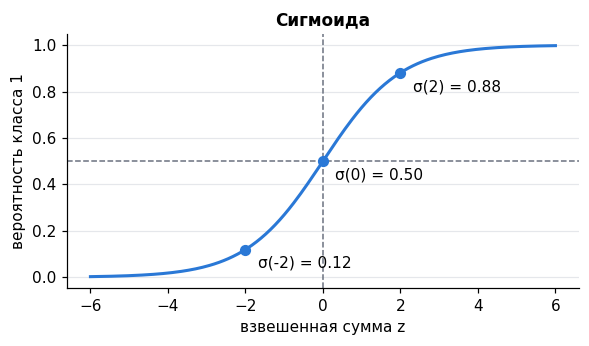

Веса: w1 = 2.26, w2 = 1.12, свободный член b = -0.32
Точка [ 0.3 -0.2]: z = 2.26·0.3 + 1.12·(-0.2) + (-0.32) = 0.14, σ(z) = 0.534, sklearn: 0.534


In [6]:
from sklearn.linear_model import LogisticRegression

z = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(z, 1 / (1 + np.exp(-z)), color=BLUE, lw=2)
ax.axhline(0.5, color=MUTED, ls="--", lw=1); ax.axvline(0, color=MUTED, ls="--", lw=1)
for zz in (-2, 0, 2):
    ax.scatter([zz], [1 / (1 + np.exp(-zz))], color=BLUE, s=40, zorder=3)
    ax.annotate(f"σ({zz}) = {1 / (1 + np.exp(-zz)):.2f}", (zz, 1 / (1 + np.exp(-zz))), textcoords="offset points", xytext=(8, -12))
ax.set_xlabel("взвешенная сумма z"); ax.set_ylabel("вероятность класса 1"); ax.set_title("Сигмоида")
ax.grid(axis="y", color=GRID)
plt.show()

logreg = LogisticRegression(C=1.0).fit(X_train, y_train)
w, b = logreg.coef_[0], logreg.intercept_[0]
print(f"Веса: w1 = {w[0]:.2f}, w2 = {w[1]:.2f}, свободный член b = {b:.2f}")
z_point = w @ point + b
print(f"Точка {point}: z = {w[0]:.2f}·{point[0]} + {w[1]:.2f}·({point[1]}) + ({b:.2f}) = {z_point:.2f}, "
      f"σ(z) = {1 / (1 + np.exp(-z_point)):.3f}, sklearn: {logreg.predict_proba([point])[0, 1]:.3f}")

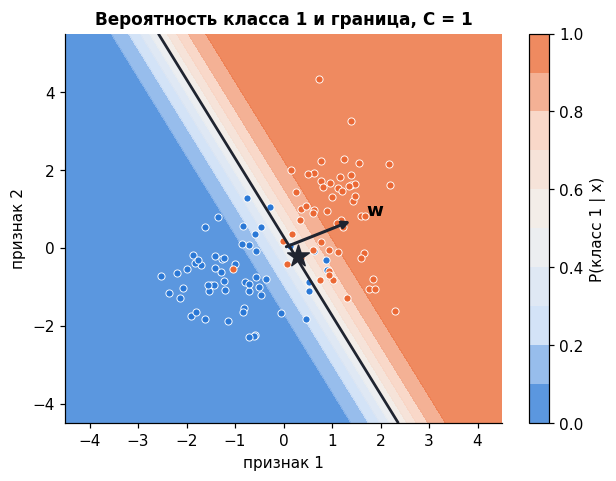

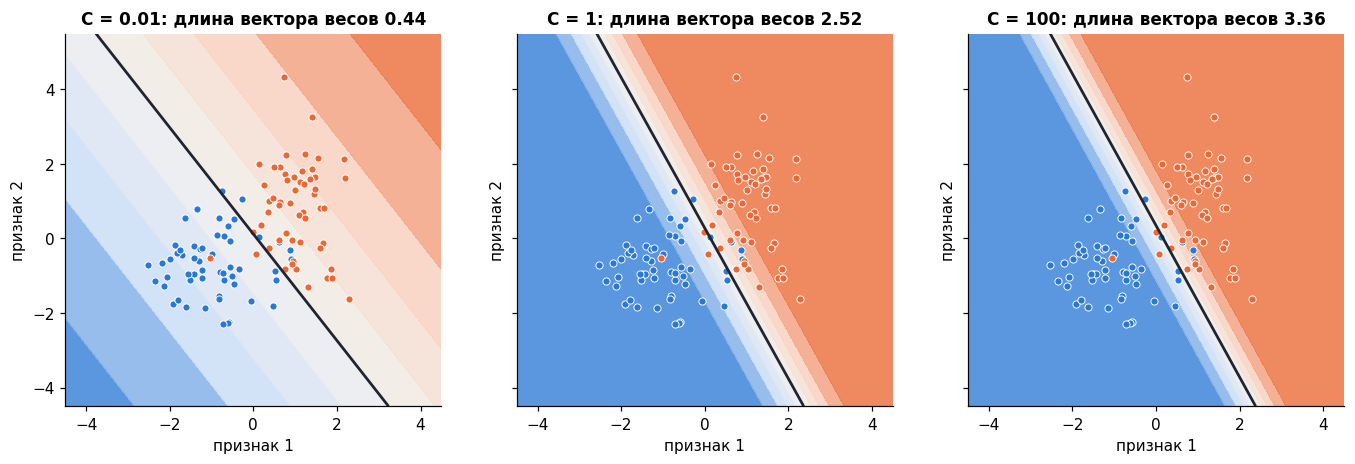

Доля верных ответов: обучение 0.929, тест 0.958


In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
im = plot_proba(ax, logreg, X_train, y_train, "Вероятность класса 1 и граница, C = 1")
ax.scatter(*point, marker="*", s=220, color="#1f2430", zorder=5)
# стрелка показывает направление вектора весов: вдоль него вероятность класса 1 растёт быстрее всего
ax.annotate("", xy=tuple(1.6 * w / np.linalg.norm(w)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2, color="#1f2430"))
ax.text(*(1.9 * w / np.linalg.norm(w)), "w", fontsize=12, fontweight="bold")
fig.colorbar(im, ax=ax, label="P(класс 1 | x)")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for ax, C in zip(axes, [0.01, 1, 100]):
    m = LogisticRegression(C=C).fit(X_train, y_train)
    plot_proba(ax, m, X_train, y_train, f"C = {C}: длина вектора весов {np.linalg.norm(m.coef_):.2f}")
plt.show()
print(f"Доля верных ответов: обучение {accuracy(logreg, X_train, y_train):.3f}, тест {accuracy(logreg, X_test, y_test):.3f}")

**Что видно на рисунке.** Граница прямая. Вероятность меняется плавно: рядом с границей модель не уверена, вдали от неё уверена. Стрелка показывает вектор весов $w$. Он перпендикулярен границе, и вдоль него вероятность класса 1 растёт быстрее всего.

Три нижние панели показывают влияние параметра `C`. Сама граница почти не сдвигается, меняется ширина светлой переходной полосы. При малом `C` веса малы и полоса широкая: модель осторожна в оценках. При большом `C` веса велики и переход резкий.

Метод сразу описывает границу и не строит модель каждого класса. Модели такого типа называются разделяющими.

## Часть 4. Линейный метод опорных векторов (SVM)

### Теория

Линейный SVM тоже проводит прямую $z=w\cdot x+b=0$. Отличие в том, как выбирается прямая. Если классы разделимы, прямых, которые их разделяют, бесконечно много. SVM выбирает ту, которая проходит на наибольшем расстоянии от ближайших точек обоих классов. Это расстояние называется зазором.

Метки классов в SVM удобно обозначать $-1$ и $+1$. Величина $M_i=y_i\,(w\cdot x_i+b)$ называется отступом объекта. Отступ положителен, если объект классифицирован верно, и тем больше, чем дальше объект от границы на своей стороне. SVM требует, чтобы у каждого объекта отступ был не меньше 1. Полоса $-1<z<1$ вокруг границы имеет ширину $2/\lVert w\rVert$, поэтому широкая полоса означает малые веса.

Данные редко разделяются без ошибок, поэтому нарушения допускаются за штраф. Штраф для объекта называется шарнирной функцией потерь (hinge loss):

$$\ell(M)=\max(0,\;1-M).$$

Объект с отступом больше 1 штрафа не получает совсем. Целевая функция складывается из двух частей:

$$\frac12\lVert w\rVert^2+C\sum_{i=1}^{n}\max\big(0,\;1-M_i\big)\;\to\;\min_{w,b}.$$

Первое слагаемое расширяет полосу, второе штрафует за нарушения. Параметр `C` задаёт цену нарушения: при большом `C` полоса узкая и нарушений мало, при малом `C` полоса широкая и нарушений больше.

Положение границы определяют только объекты на краю полосы и внутри неё. Они называются **опорными векторами**. Остальные объекты можно убрать из выборки, и граница не изменится.

SVM выдаёт значение $z$, вероятностей он не выдаёт. Класс определяется знаком $z$.

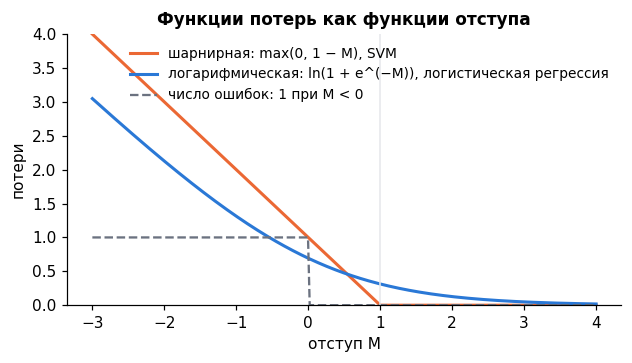

In [8]:
M = np.linspace(-3, 4, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(M, np.maximum(0, 1 - M), color=ORANGE, lw=2, label="шарнирная: max(0, 1 − M), SVM")
ax.plot(M, np.log(1 + np.exp(-M)), color=BLUE, lw=2, label="логарифмическая: ln(1 + e^(−M)), логистическая регрессия")
ax.plot(M, (M < 0).astype(float), color=MUTED, lw=1.5, ls="--", label="число ошибок: 1 при M < 0")
ax.axvline(1, color=GRID, lw=1)
ax.set_xlabel("отступ M"); ax.set_ylabel("потери"); ax.set_ylim(0, 4); ax.legend(frameon=False, fontsize=9)
ax.set_title("Функции потерь как функции отступа")
plt.show()

**Что видно на рисунке.** Обе функции потерь штрафуют ошибки (отрицательный отступ) тем сильнее, чем грубее ошибка. Различие справа от единицы. Шарнирная функция равна нулю: объект, который классифицирован верно с запасом, на решение больше не влияет. Логарифмическая функция к нулю только приближается: каждый объект, даже очень далёкий, продолжает немного влиять на веса.

В двумерном примере используется класс `SVC(kernel="linear")`: он хранит список опорных векторов, и их можно нарисовать. Для текстов в части 6 берётся `LinearSVC`: он решает ту же задачу и работает быстрее при большом числе признаков.

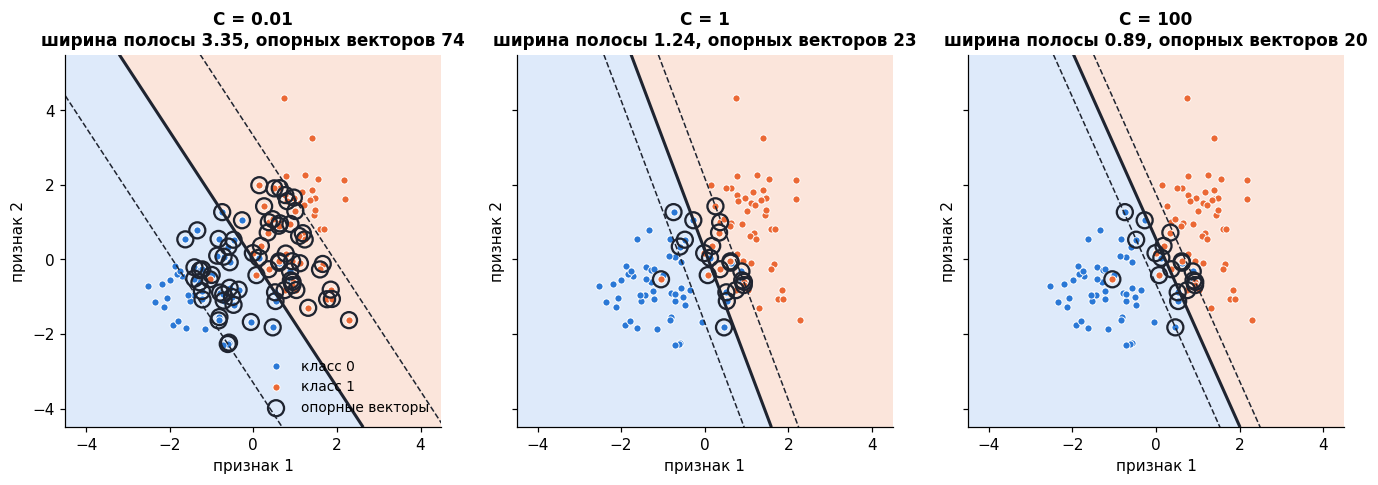

C = 1. Доля верных ответов: обучение 0.920, тест 0.938
Опорных векторов 23 из 112 обучающих точек


In [9]:
from sklearn.svm import SVC


def plot_svm(ax, clf, X, y, title=""):
    zz = clf.decision_function(GRID_POINTS).reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=[-100, 0, 100], colors=["#dbe8fa", "#fbe3d8"], alpha=0.9)
    ax.contour(gx, gy, zz, levels=[-1, 0, 1], colors="#1f2430", linewidths=[1, 2, 1], linestyles=["--", "-", "--"])
    scatter(ax, X, y)
    sv = clf.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=110, facecolor="none", edgecolor="#1f2430", linewidth=1.5, label="опорные векторы")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for ax, C in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=C).fit(X_train, y_train)
    plot_svm(ax, m, X_train, y_train,
             f"C = {C}\nширина полосы {2 / np.linalg.norm(m.coef_):.2f}, опорных векторов {len(m.support_vectors_)}")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

svm = SVC(kernel="linear", C=1).fit(X_train, y_train)
print(f"C = 1. Доля верных ответов: обучение {accuracy(svm, X_train, y_train):.3f}, тест {accuracy(svm, X_test, y_test):.3f}")
print(f"Опорных векторов {len(svm.support_vectors_)} из {len(X_train)} обучающих точек")

**Что видно на рисунке.** Сплошная линия показывает границу, пунктирные линии показывают края полосы, на которых $z=\pm1$. Обведены опорные векторы: точки на краях полосы, внутри неё и на чужой стороне. При малом `C` полоса широкая и опорных векторов много. При большом `C` полоса сужается, и границу определяет небольшое число точек рядом с ней.

Проверим утверждение из теории: если убрать все точки, кроме опорных, граница не изменится.

In [10]:
sv_idx = svm.support_
svm_sv_only = SVC(kernel="linear", C=1).fit(X_train[sv_idx], y_train[sv_idx])
print("Модель на всех точках:           w =", np.round(svm.coef_[0], 3), " b =", np.round(svm.intercept_[0], 3))
print("Модель только на опорных векторах: w =", np.round(svm_sv_only.coef_[0], 3), " b =", np.round(svm_sv_only.intercept_[0], 3))

Модель на всех точках:           w = [1.534 0.515]  b = -0.13
Модель только на опорных векторах: w = [1.534 0.515]  b = -0.13


## Часть 5. Три метода рядом

Рисунок повторяет слайд лекции: три метода обучены на одних и тех же точках.

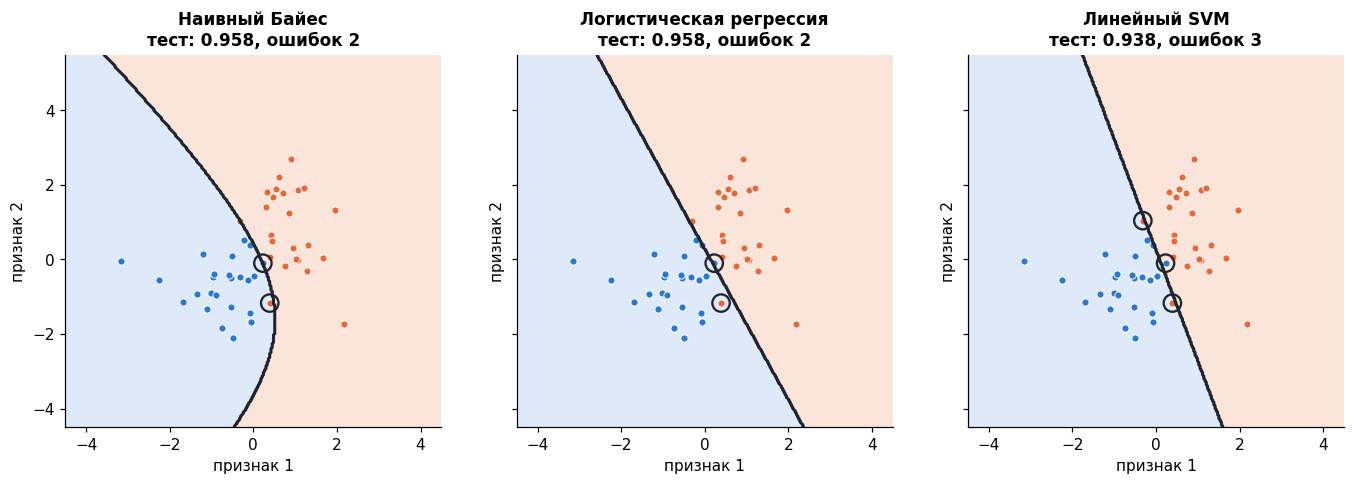

,обучение,тест
Наивный Байес,0.920,0.958
Логистическая регрессия,0.929,0.958
Линейный SVM,0.920,0.938


In [11]:
models_2d = {"Наивный Байес": nb, "Логистическая регрессия": logreg, "Линейный SVM": svm}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models_2d.items()):
    pred = m.predict(GRID_POINTS).reshape(gx.shape)
    ax.contourf(gx, gy, pred, levels=[-0.5, 0.5, 1.5], colors=["#dbe8fa", "#fbe3d8"], alpha=0.9)
    ax.contour(gx, gy, pred, levels=[0.5], colors="#1f2430", linewidths=2)
    scatter(ax, X_test, y_test)
    wrong = m.predict(X_test) != y_test
    ax.scatter(X_test[wrong, 0], X_test[wrong, 1], s=130, facecolor="none", edgecolor="#1f2430", linewidth=1.5)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_title(f"{name}\nтест: {accuracy(m, X_test, y_test):.3f}, ошибок {int(wrong.sum())}")
plt.show()

summary = pd.DataFrame({name: {"обучение": accuracy(m, X_train, y_train), "тест": accuracy(m, X_test, y_test)}
                        for name, m in models_2d.items()}).T
display(summary.round(3))

**Что видно на рисунке.** Показаны тестовые точки, ошибки обведены. Граница наивного Байеса изогнута, границы двух других методов прямые и близки друг к другу. Ошибки сосредоточены в области, где группы перекрываются, и у трёх методов они почти одни и те же. Доли верных ответов близки: на простых данных все три метода работают хорошо, и различия между ними проявляются в другом.

### Реакция на удалённые точки

Добавим в обучающую выборку шесть точек класса 1 далеко в правом верхнем углу. Они лежат на своей стороне и в классификации не вызывают сомнений. Изменится ли граница?

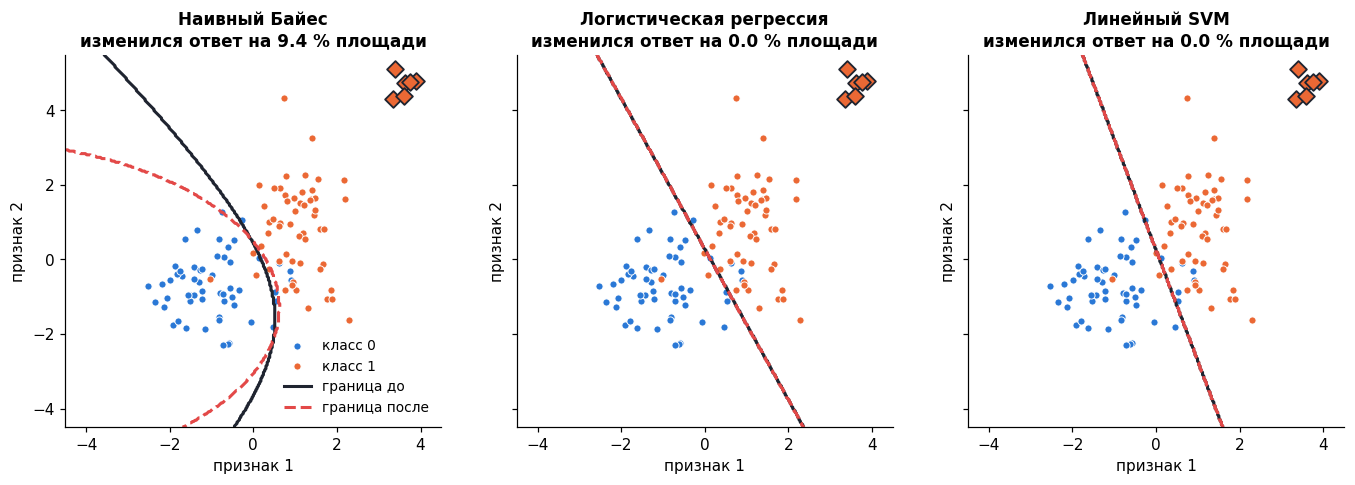

In [12]:
far = rng.normal(loc=[3.6, 4.6], scale=0.25, size=(6, 2))
X_far = np.vstack([X_train, far]); y_far = np.r_[y_train, np.ones(6, dtype=int)]

fitters = {"Наивный Байес": lambda: GaussianNB(), "Логистическая регрессия": lambda: LogisticRegression(C=1.0),
           "Линейный SVM": lambda: SVC(kernel="linear", C=1)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for ax, (name, make) in zip(axes, fitters.items()):
    before = models_2d[name].predict(GRID_POINTS).reshape(gx.shape)
    after = make().fit(X_far, y_far).predict(GRID_POINTS).reshape(gx.shape)
    ax.contour(gx, gy, before, levels=[0.5], colors="#1f2430", linewidths=2)
    ax.contour(gx, gy, after, levels=[0.5], colors="#e34948", linewidths=2, linestyles="--")
    scatter(ax, X_train, y_train)
    ax.scatter(far[:, 0], far[:, 1], s=60, color=ORANGE, edgecolor="#1f2430", linewidth=1.2, marker="D")
    ax.plot([], [], color="#1f2430", lw=2, label="граница до"); ax.plot([], [], color="#e34948", lw=2, ls="--", label="граница после")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_title(f"{name}\nизменился ответ на {100 * (before != after).mean():.1f} % площади")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

**Что видно на рисунке.** Новые точки показаны ромбами. Граница SVM не изменилась: новые точки далеко от полосы и опорными векторами не стали. Граница логистической регрессии практически не изменилась: далёкие точки продолжают влиять на веса, и влияние это очень мало. Граница наивного Байеса изменилась сильнее всего: новые точки сдвинули среднее и увеличили разброс класса 1, то есть изменили саму модель класса.

Отсюда практическое различие. Наивный Байес чувствителен к тому, насколько данные класса соответствуют выбранному распределению. Разделяющие методы смотрят прежде всего на область около границы.

## Часть 6. Те же три метода на текстах

Теперь объектом служит новость Lenta.ru, классом служит её рубрика: «Экономика» или «Наука и техника». Рубрики близки по лексике: в обеих пишут о компаниях, проектах и деньгах, поэтому задача не тривиальна. Файл `data/lenta_ru_short.jsonl` создаётся на семинаре 0.

Текст превращается в вектор по схеме из лекции 2: каждому слову словаря соответствует признак, значение признака равно весу TF-IDF слова в новости. Признаков несколько тысяч, и нарисовать границу нельзя. Сами методы остаются теми же, с одним уточнением: для наивного Байеса вместо нормального распределения берётся мультиномиальная модель `MultinomialNB`. Вероятность слова в классе оценивается его долей среди слов класса со сглаживанием:

$$P(w\mid c)=\frac{n_{wc}+\alpha}{n_c+\alpha\,|V|},$$

где $n_{wc}$ обозначает суммарный вес слова $w$ в текстах класса $c$, $n_c$ суммарный вес всех слов класса, $|V|$ размер словаря, $\alpha$ параметр сглаживания.

In [13]:
def find_data(name):
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / "data" / name).exists():
            return parent / "data" / name
    raise FileNotFoundError(f"Файл data/{name} не найден. Выполните семинар 0: он загружает данные курса.")


rows = [json.loads(line) for line in open(find_data("lenta_ru_short.jsonl"), encoding="utf-8")]
rows = [r for r in rows if r["topic"] in ("Экономика", "Наука и техника")]
texts = [(r["title"] + ". " + r["text"]).replace("\xa0", " ") for r in rows]
labels = np.array([1 if r["topic"] == "Наука и техника" else 0 for r in rows])      # 1: наука и техника, 0: экономика
CLASS_NAMES = ["экономика", "наука и техника"]
print(f"Новостей: {len(texts)}, «Экономика» {(1 - labels).sum()}, «Наука и техника» {labels.sum()}")
print("Пример, экономика:", texts[int(np.argmin(labels))][:200], "...")
print("Пример, наука и техника:", texts[int(np.argmax(labels))][:200], "...")

T_train, T_test, l_train, l_test = train_test_split(texts, labels, test_size=0.25, stratify=labels, random_state=SEED)

Новостей: 1776, «Экономика» 936, «Наука и техника» 840
Пример, экономика: Торговля в США начинает оживляться. Согласно данным министерства торговли США, в июле товарные запасы американских оптовиков снизились на 0,7 процента, что является их самым резким падением с сентября ...
Пример, наука и техника: Офицер ВВС России приговорен к четырем годам за столкновение двух Ми-24. РИА "Новости" ...


In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC


def vectorizer():
    # слова из двух и более букв, встретившиеся хотя бы в трёх новостях; sublinear_tf сглаживает частоты
    return TfidfVectorizer(lowercase=True, token_pattern=r"[а-яёa-z]{2,}", min_df=3, sublinear_tf=True)


text_models = {
    "Постоянный ответ (baseline)": lambda: make_pipeline(vectorizer(), DummyClassifier(strategy="most_frequent")),
    "Наивный Байес": lambda: make_pipeline(vectorizer(), MultinomialNB(alpha=0.5)),
    "Логистическая регрессия": lambda: make_pipeline(vectorizer(), LogisticRegression(C=10, max_iter=2000)),
    "Линейный SVM": lambda: make_pipeline(vectorizer(), LinearSVC(C=1)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, rows_res = {}, []
for name, make in text_models.items():
    scores = cross_val_score(make(), T_train, l_train, cv=cv, scoring="f1_macro")     # кросс-валидация на обучающей части
    fitted[name] = make().fit(T_train, l_train)
    pred = fitted[name].predict(T_test)
    rows_res.append({"модель": name, "macro-F1, кросс-валидация": scores.mean(), "разброс по частям": scores.std(),
                     "доля верных, тест": (pred == l_test).mean(), "macro-F1, тест": f1_score(l_test, pred, average="macro")})
res = pd.DataFrame(rows_res).set_index("модель")
print("Размер словаря:", len(fitted["Наивный Байес"][0].vocabulary_))
display(res.round(3))

Размер словаря: 3860


,"macro-F1, кросс-валидация",разброс по частям,"доля верных, тест","macro-F1, тест"
модель,,,,
Постоянный ответ (baseline),0.345,0.000,0.527,0.345
Наивный Байес,0.950,0.004,0.962,0.961
Логистическая регрессия,0.940,0.007,0.966,0.966
Линейный SVM,0.938,0.011,0.957,0.957


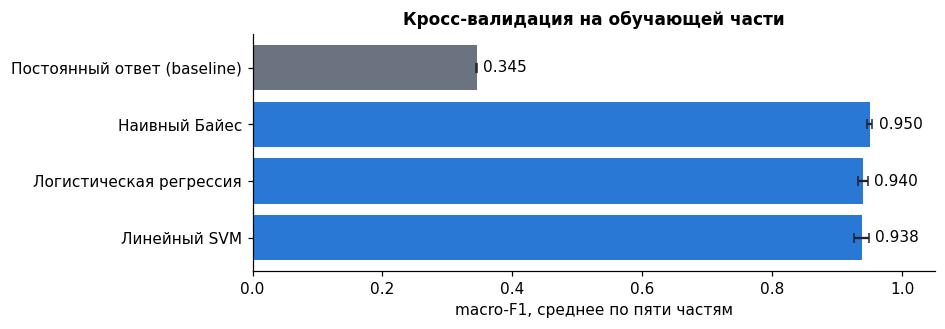

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.8))
names = list(res.index)[::-1]
ax.barh(names, res.loc[names, "macro-F1, кросс-валидация"], xerr=res.loc[names, "разброс по частям"],
        color=[BLUE if "baseline" not in n else MUTED for n in names], error_kw=dict(ecolor="#1f2430", capsize=3))
for i, n in enumerate(names):
    ax.text(res.loc[n, "macro-F1, кросс-валидация"] + res.loc[n, "разброс по частям"] + 0.01, i,
            f"{res.loc[n, 'macro-F1, кросс-валидация']:.3f}", va="center")
ax.set_xlim(0, 1.05); ax.set_xlabel("macro-F1, среднее по пяти частям"); ax.set_title("Кросс-валидация на обучающей части")
plt.show()

**Что видно на рисунке.** Столбцы показывают среднее значение macro-F1 по пяти частям кросс-валидации, отрезки показывают разброс между частями. Постоянный ответ даёт macro-F1 около одной трети: модель, которая всегда называет один класс, полностью теряет второй. Все три метода намного лучше этой точки отсчёта. Различия между тремя методами нужно сравнивать с разбросом: если отрезки перекрываются, утверждать, что один метод лучше другого, нельзя.

### Матрицы ошибок

Матрица ошибок показывает, какие именно ошибки делает модель на тестовых новостях.

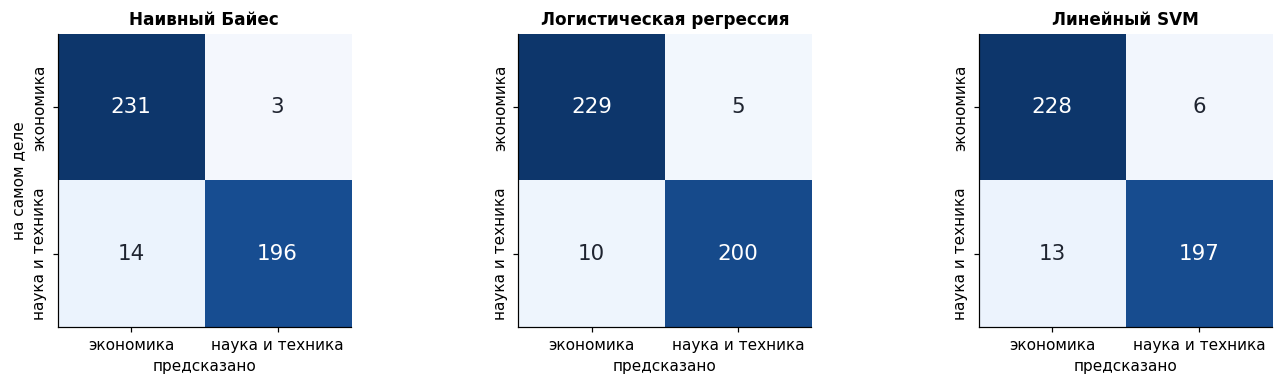

In [16]:
main = ["Наивный Байес", "Логистическая регрессия", "Линейный SVM"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, main):
    cm = confusion_matrix(l_test, fitted[name].predict(T_test))
    ax.imshow(cm, cmap=SEQ, vmin=0, vmax=cm.sum() / 2)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.sum() / 4 else "#1f2430")
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks([0, 1]); ax.set_yticklabels(CLASS_NAMES, rotation=90, va="center")
    ax.set_xlabel("предсказано"); ax.set_title(name)
axes[0].set_ylabel("на самом деле")
fig.tight_layout()
plt.show()

### Насколько уверенно модели разделяют классы

Каждая из трёх моделей вычисляет для новости число, по знаку которого выбирается класс. У логистической регрессии и SVM это взвешенная сумма $z$, у наивного Байеса разность логарифмов вероятностей двух классов. Гистограммы показывают распределение этого числа для тестовых новостей каждого класса. Чем меньше перекрываются две гистограммы, тем лучше модель разделяет классы.

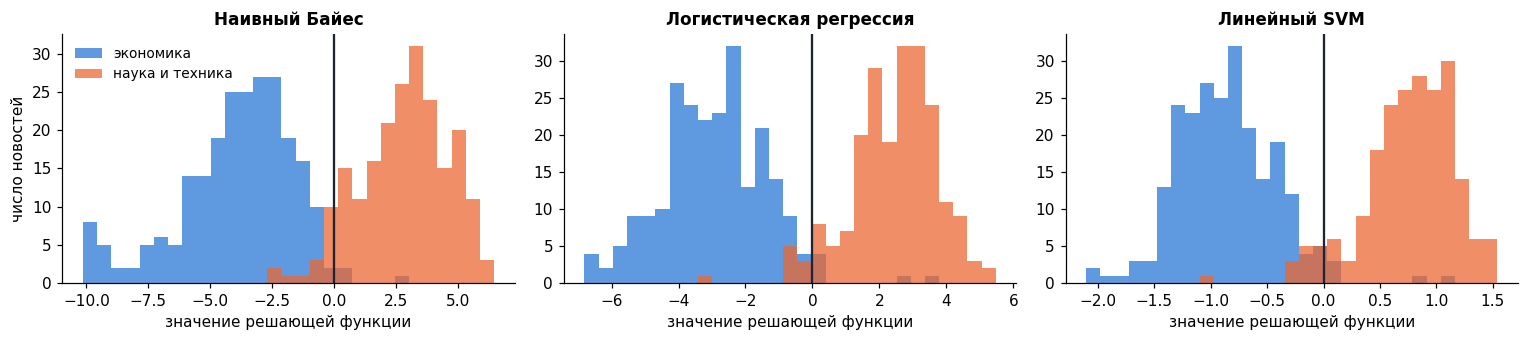

In [17]:
def decision_score(pipe, T):
    vec, clf = pipe[0], pipe[1]
    Xv = vec.transform(T)
    if hasattr(clf, "decision_function"):
        return clf.decision_function(Xv)
    lp = clf.predict_log_proba(Xv)
    return lp[:, 1] - lp[:, 0]


fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, name in zip(axes, main):
    s = decision_score(fitted[name], T_test)
    bins = np.linspace(s.min(), s.max(), 30)
    ax.hist(s[l_test == 0], bins=bins, color=BLUE, alpha=0.75, label="экономика")
    ax.hist(s[l_test == 1], bins=bins, color=ORANGE, alpha=0.75, label="наука и техника")
    ax.axvline(0, color="#1f2430", lw=1.5)
    ax.set_title(name); ax.set_xlabel("значение решающей функции")
axes[0].set_ylabel("число новостей"); axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Какие слова решают

У линейных моделей вес слова показывает, в какую сторону и насколько сильно слово сдвигает решение. Для наивного Байеса аналогом веса служит разность логарифмов вероятностей слова в двух классах: $\ln P(w\mid\text{наука})-\ln P(w\mid\text{экономика})$.

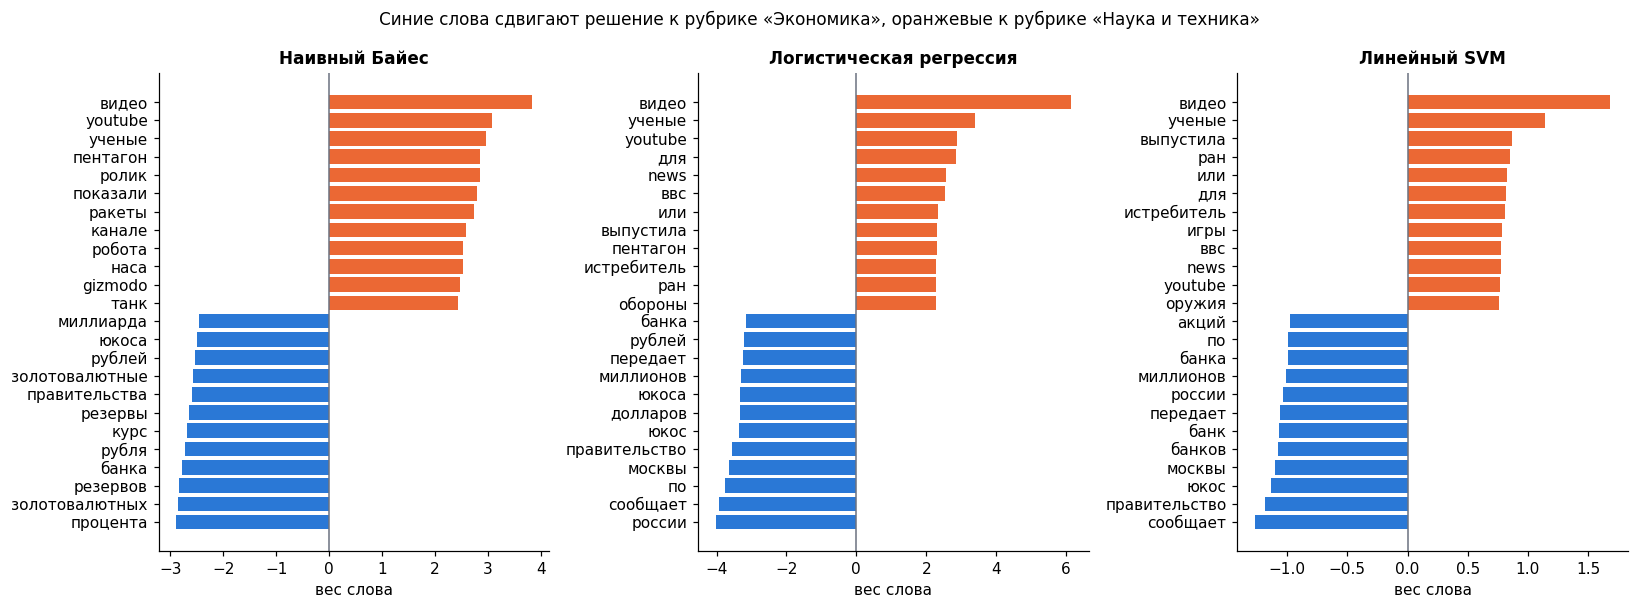

In [18]:
def word_weights(pipe):
    vec, clf = pipe[0], pipe[1]
    words = np.array(vec.get_feature_names_out())
    wts = clf.coef_[0] if hasattr(clf, "coef_") else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    return words, wts


fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
fig.suptitle("Синие слова сдвигают решение к рубрике «Экономика», оранжевые к рубрике «Наука и техника»", fontsize=11)
for ax, name in zip(axes, main):
    words, wts = word_weights(fitted[name])
    order = np.r_[np.argsort(wts)[:12], np.argsort(wts)[-12:]]
    ax.barh(words[order], wts[order], color=[ORANGE if v > 0 else BLUE for v in wts[order]])
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(name); ax.set_xlabel("вес слова")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Логистическая регрессия и SVM выделяют похожие слова: лексику, которая часто встречается в новостях одной рубрики и редко в другой. Список наивного Байеса устроен иначе. В него попадают слова, которые встретились в новостях только одной рубрики, в том числе редкие: при малом числе вхождений отношение вероятностей получается большим. Параметр сглаживания $\alpha$ уменьшает этот эффект.

### Разбор одной новости

Для короткого текста можно посмотреть вклад каждого слова в решение логистической регрессии: вклад равен произведению веса слова на его значение TF-IDF в тексте.

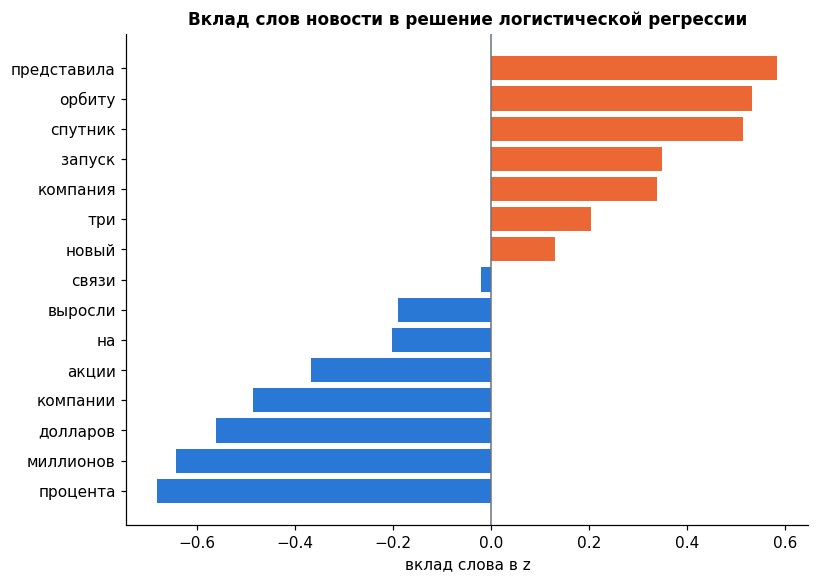

Текст: Компания представила новый спутник связи. Запуск на орбиту обойдётся в 200 миллионов долларов, акции компании выросли на три процента.
  Наивный Байес: наука и техника, значение решающей функции +0.40
  Логистическая регрессия: наука и техника, значение решающей функции +0.49
  Линейный SVM: наука и техника, значение решающей функции +0.27


In [19]:
review = "Компания представила новый спутник связи. Запуск на орбиту обойдётся в 200 миллионов долларов, акции компании выросли на три процента."
pipe = fitted["Логистическая регрессия"]
vec, clf = pipe[0], pipe[1]
xv = vec.transform([review])
names = vec.get_feature_names_out()
contrib = sorted(((names[j], xv[0, j] * clf.coef_[0][j]) for j in xv.nonzero()[1]), key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(8, 0.32 * len(contrib) + 1))
ax.barh([w for w, _ in contrib], [c for _, c in contrib], color=[ORANGE if c > 0 else BLUE for _, c in contrib])
ax.axvline(0, color=MUTED, lw=1); ax.set_xlabel("вклад слова в z")
ax.set_title("Вклад слов новости в решение логистической регрессии")
plt.show()
print("Текст:", review)
for name in main:
    print(f"  {name}: {CLASS_NAMES[int(fitted[name].predict([review])[0])]}, значение решающей функции {decision_score(fitted[name], [review])[0]:+.2f}")

**Что видно на рисунке.** Текст смешанный: в нём есть и космическая, и финансовая лексика, и слова сдвигают решение в разные стороны. Итог определяется суммой вкладов. Слова, которых не было в обучающих новостях, в сумму не входят: модель их не видит.

## Итог

| | Наивный Байес | Логистическая регрессия | Линейный SVM |
|---|---|---|---|
| Что строит | модель каждого класса | границу и вероятность класса | границу с наибольшим зазором |
| Предположение | признаки независимы при известном классе | логарифм отношения вероятностей линеен по признакам | классы разделяются линейно с небольшим числом нарушений |
| Обучение | подсчёт частот, один проход | численная минимизация логарифмических потерь | численная минимизация шарнирных потерь |
| Что выдаёт | вероятности, часто слишком уверенные | вероятности | значение $z$ без вероятностей |
| Главный параметр | сглаживание $\alpha$ | сила регуляризации `C` | цена нарушений `C` |
| Какие объекты влияют на решение | все, через средние и частоты | все, далёкие от границы слабо | только опорные векторы |

## Часть 7. Вопросы

На каждый вопрос требуется письменный ответ в три-пять фраз в ячейке под вопросом. Там, где сказано «проверьте», ответ подтверждается кодом и числом или рисунком.

**Вопрос 1. Предположение наивного Байеса.** В чём состоит предположение метода и почему оно названо наивным? Приведите пример двух слов из новостей, для которых оно заведомо нарушается. Как нарушение скажется на вероятностях, которые выдаёт модель?

**Вопрос 2. Сглаживание.** Слово «телескоп» встретилось в обучающих новостях рубрики «Наука и техника» и ни разу не встретилось в рубрике «Экономика». Какую вероятность получит рубрика «Экономика» для новости с этим словом при $\alpha=0$? Что меняет $\alpha>0$? Проверьте: обучите `MultinomialNB` с $\alpha\in\{0.01,\,0.5,\,5\}$ и сравните macro-F1 на кросс-валидации.

**Вопрос 3. Веса и вероятность.** У слова в логистической регрессии вес равен $+1.5$. Что это означает? Взвешенная сумма для новости равна $z=0$. Какой станет вероятность класса 1, если добавить в текст слова с суммарным вкладом $+2$? Как изменятся веса при уменьшении параметра `C` и почему?

**Вопрос 4. Опорные векторы.** Какие объекты называются опорными векторами? Из обучающей выборки удалили объект, лежащий далеко от границы на своей стороне. Изменится ли граница SVM? Граница логистической регрессии? Граница наивного Байеса? Сошлитесь на рисунок из части 5.

**Вопрос 5. Функции потерь.** Объект классифицирован верно, его отступ равен 3. Чему равны для него шарнирные потери и логарифмические потери? Какое следствие это имеет для обучения двух методов? Что изменится для объекта с отступом $-3$?

**Вопрос 6. Выбор метода.** По результатам части 6 ответьте, какой метод вы выберете в каждом из трёх случаев и почему: (а) размеченных новостей всего 50, (б) редактору нужно показать, какие слова повлияли на решение, и вероятность ошибки, (в) новостей сто тысяч, и важна только доля верных ответов. Почему в этой задаче долю верных ответов можно использовать как меру качества, и что изменится, если новостей одной рубрики станет 95 %?

**Ответ на вопрос 1.**

_Напишите ответ здесь._

**Ответ на вопрос 2.**

_Напишите ответ здесь._

In [20]:
# Проверка к вопросу 2. Ваш код:

**Ответ на вопрос 3.**

_Напишите ответ здесь._

**Ответ на вопрос 4.**

_Напишите ответ здесь._

**Ответ на вопрос 5.**

_Напишите ответ здесь._

**Ответ на вопрос 6.**

_Напишите ответ здесь._